# Logistic Regression from Scratch: One-vs-All Classification

The continuous human-zombie score is turned into **three classes**, and a **regularised logistic regression written from scratch in NumPy** is extended to multiclass with **One-vs-All (OvA)**. The result is then compared with scikit-learn's `LogisticRegression`.

| Class | Score range | Decision |
|---|---|---|
| 0 | 0–33 | Most likely human: board the ship |
| 1 | 33–66 | Needs further tests: quarantine |
| 2 | 66–100 | Most likely zombie: deny entry |

*Course context: Machine Learning programming assignment (PA2, Task 2), LUMS. The dataset is synthetic.*

## One-vs-All
For each of the *m* classes, a binary logistic regression learns "this class vs. all the others". At prediction time every model outputs a probability, and the class with the **highest probability** wins.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

## Dataset
The same 1,000-row dataset as the linear regression notebook.

In [2]:
# load dataset and print first few rows
data_path = 'data/human_zombie_dataset_v5.csv'
data = pd.read_csv(data_path)

data.head()

,Height (cm),Weight (kg),Screen Time (hrs),Junk Food (days/week),Physical Activity (hrs/week),Task Completion (scale),Human-Zombie Score
0,157,41,8.455099,5.622736,4.474819,6.166119,54.881350
1,151,40,8.581430,5.922744,3.749707,1.084877,71.518937
2,166,45,5.018847,5.746557,4.596662,2.030814,60.276338
3,160,75,6.417010,4.634547,4.546153,3.360430,54.488318
4,153,74,4.417465,4.740153,6.601801,5.758603,42.365480


## Preprocessing
1. Convert the continuous score into the 3 classes above.
2. 80/20 train/test split.
3. Standardise with the custom scaler (statistics from the training set only).

In [3]:
# Transform Labels

def transform_labels(scores):
    categories = []
    for score in scores:
        if 0 <= score <= 33:
            categories.append(0)  
        elif 33 < score <= 66:
            categories.append(1) 
        else:
            categories.append(2)  
    return categories

data['Category'] = transform_labels(data['Human-Zombie Score'])
print(data[['Human-Zombie Score', 'Category']].head())


   Human-Zombie Score  Category
0           54.881350         1
1           71.518937         2
2           60.276338         1
3           54.488318         1
4           42.365480         1


In [4]:
# Train Test Split
X = data.drop(columns=['Human-Zombie Score', 'Category']).values
y = data['Category'].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")

Training set size: 800 samples
Test set size: 200 samples


In [5]:

class StandardScaler:
    def __init__(self):
        self.mean = None
        self.std = None
    
    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)
    
    def transform(self, X):
        if self.mean is None or self.std is None:
            raise ValueError("Scaler not fitted yet.")
        return (X - self.mean) / self.std
    
    def fit_transform(self, X):
        self.fit(X)
        return self.transform(X)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"First 5 rows of normalized training data:\n{X_train_scaled[:5]}")


First 5 rows of normalized training data:
[[-0.84687364 -0.40609255 -0.12331522 -0.51572628  0.15034095  0.3438235 ]
 [ 0.26560405 -0.00722939 -1.18997624 -1.80275457  1.34354877  0.90072801]
 [ 0.98076828 -0.27313816 -0.09644533 -0.45253362  0.41888558  0.22796347]
 [ 0.26560405  0.65754253  0.45469761 -0.40453707  0.44811382  0.58169707]
 [-1.24418711 -1.20381886  1.82826196  1.02608432 -1.7051533  -0.83660921]]


## Part A: Regularised logistic regression from scratch (NumPy only)
`RegularizedLogisticRegression` implements:
- `sigmoid`
- `cross_entropy_loss`: binary cross-entropy + L2 penalty
- `fit`: batch gradient descent, returning the loss history
- `predict`: probabilities and labels at a 0.5 threshold
- `evaluate`: accuracy, F1 and the confusion matrix, computed by hand

In [6]:


class RegularizedLogisticRegression:
    def __init__(self, learning_rate=0.01, iterations=1000, regularization_strength=0.1):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.regularization_strength = regularization_strength
        self.weights = None
        self.bias = None

    def sigmoid(self, x):
        """
       
        """
        return 1 / (1 + np.exp(-x))

    def cross_entropy_loss(self, y_true, y_pred):
        """
        Binary Cross Entropy Loss with L2 regularization.
        """
        m = y_true.shape[0]
        epsilon = 1e-15  
        loss = -(1 / m) * np.sum(
            y_true * np.log(y_pred + epsilon) + (1 - y_true) * np.log(1 - y_pred + epsilon)
        )
        reg_term = (self.regularization_strength / (2 * m)) * np.sum(self.weights**2)
        return loss + reg_term

    def fit(self, X_train, y_train):
        """
        Fit the model using Gradient Descent and return the cost history.
        """
        n_samples, n_features = X_train.shape
        self.weights = np.zeros(n_features)
        self.bias = 0
        cost_history = []  

        for _ in range(self.iterations):
            linear_model = np.dot(X_train, self.weights) + self.bias
            y_pred = self.sigmoid(linear_model)

            loss = self.cross_entropy_loss(y_train, y_pred)
            cost_history.append(loss)

            dw = (1 / n_samples) * np.dot(X_train.T, (y_pred - y_train)) + (self.regularization_strength / n_samples) * self.weights
            db = (1 / n_samples) * np.sum(y_pred - y_train)
            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

        return cost_history


    def predict(self, X_test):
        """
        Predict probabilities and binary labels.
        """
        linear_model = np.dot(X_test, self.weights) + self.bias
        y_prob = self.sigmoid(linear_model)
        y_pred = np.where(y_prob >= 0.5, 1, 0)
        return y_prob, y_pred

    def evaluate(self, y_true, y_pred):
        """
        Evaluate model performance: calculate accuracy, F1 score, and confusion matrix.
        """
        accuracy = np.sum(y_true == y_pred) / len(y_true)

        tp = np.sum((y_true == 1) & (y_pred == 1))
        fp = np.sum((y_true == 0) & (y_pred == 1))
        fn = np.sum((y_true == 1) & (y_pred == 0))
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

        tn = np.sum((y_true == 0) & (y_pred == 0))
        cm = np.array([[tn, fp], [fn, tp]])

        print(f"Accuracy: {accuracy:.4f}")
        print(f"F1 Score: {f1:.4f}")
        print("Confusion Matrix:")
        print(cm)
        return accuracy, f1, cm


## One-vs-All training
Three binary classifiers (learning rate 0.04, 5,000 iterations, L2 strength 0.1), with their training loss curves.

Evaluation for Class 0:
Accuracy: 0.9650
F1 Score: 0.9440
Confusion Matrix:
[[134   5]
 [  2  59]]


Evaluation for Class 1:
Accuracy: 0.6200
F1 Score: 0.0000
Confusion Matrix:
[[124   0]
 [ 76   0]]


Evaluation for Class 2:
Accuracy: 0.9500
F1 Score: 0.9219
Confusion Matrix:
[[131   6]
 [  4  59]]


Final Train Loss for Class 0: 0.1133
Final Train Loss for Class 1: 0.6156
Final Train Loss for Class 2: 0.1117


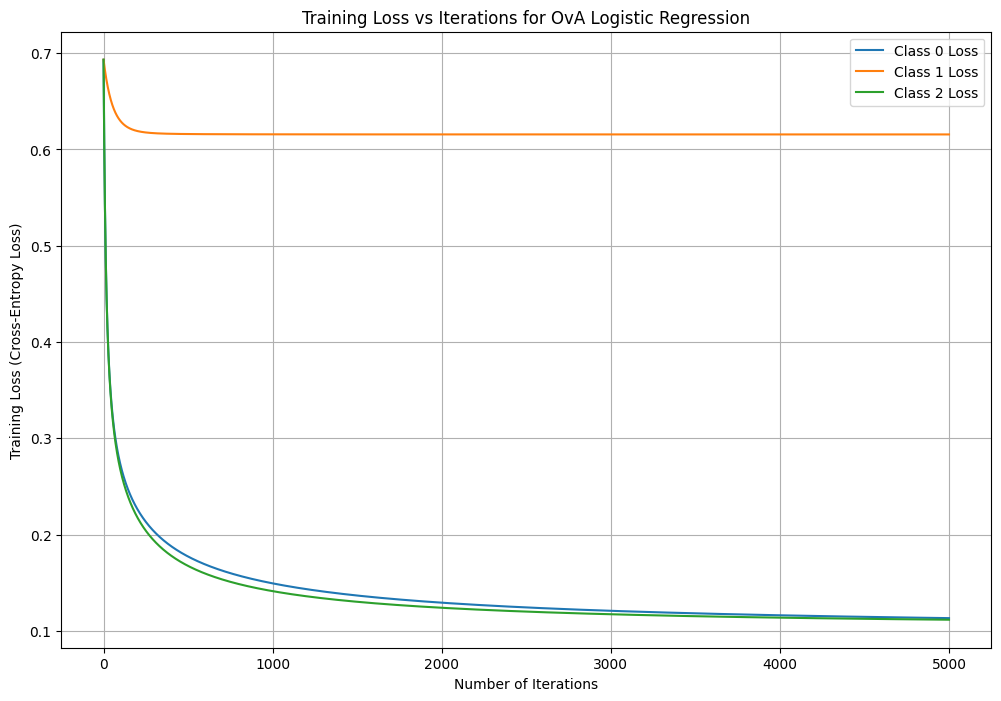

In [7]:
classifiers = {}
losses = {}

num_classes = 3 

learning_rate = 0.04
iterations = 5000
regularization_strength = 0.1

for i in range(num_classes):

    y_binary_train = (y_train == i).astype(int) 
    y_binary_val = (y_test == i).astype(int)  
    
    model = RegularizedLogisticRegression(
        learning_rate=learning_rate,
        iterations=iterations,
        regularization_strength=regularization_strength
    )
    
    cost_history = model.fit(X_train_scaled, y_binary_train)
    classifiers[i] = model 
    losses[i] = cost_history  
    
    y_prob_val, y_pred_val = model.predict(X_test_scaled)
    
    print(f"Evaluation for Class {i}:")
    model.evaluate(y_binary_val, y_pred_val)
    print("\n")

for i in range(num_classes):
    final_train_loss = losses[i][-1]  
    print(f"Final Train Loss for Class {i}: {final_train_loss:.4f}")
plt.figure(figsize=(12, 8))
for i in range(num_classes):
    plt.plot(range(len(losses[i])), losses[i], label=f'Class {i} Loss')
    
plt.xlabel('Number of Iterations')
plt.ylabel('Training Loss (Cross-Entropy Loss)')
plt.title('Training Loss vs Iterations for OvA Logistic Regression')
plt.legend()
plt.grid(True)
plt.show()





## Evaluation
Per-class binary metrics, then the combined multiclass prediction: accuracy, macro F1 and the confusion matrix, all computed by hand.

In [8]:
results = {
    'Class': [],
    'Probs': [],
    'Accuracy': [],
    'F1 Score': [],
    'Confusion Matrix': []
}

for i in range(num_classes):
    probability, predicted_class = classifiers[i].predict(X_test_scaled)

    tp = np.sum((y_test == i) & (predicted_class == 1))
    fp = np.sum((y_test != i) & (predicted_class == 1))
    fn = np.sum((y_test == i) & (predicted_class == 0))
    tn = np.sum((y_test != i) & (predicted_class == 0))
    
    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if precision + recall > 0 else 0
    cm = np.array([[tn, fp], [fn, tp]])
    
    accuracy = (tp + tn) / (tp + tn + fp + fn)
 
    results['Class'].append(i)
    results['Probs'].append(probability)
    results['Accuracy'].append(accuracy)
    results['F1 Score'].append(f1)
    results['Confusion Matrix'].append(cm)

results_df = pd.DataFrame(results)
print(results_df)


   Class                                              Probs  Accuracy  \
0      0  [0.6679757762148708, 0.005796085934958787, 0.9...     0.965   
1      1  [0.3527512388871635, 0.2938561410237012, 0.238...     0.620   
2      2  [0.000373697711308498, 0.13191548018746652, 7....     0.950   

   F1 Score     Confusion Matrix  
0  0.944000  [[134, 5], [2, 59]]  
1  0.000000  [[124, 0], [76, 0]]  
2  0.921875  [[131, 6], [4, 59]]  


In [9]:
results_df.drop('Probs',axis=1)

,Class,Accuracy,F1 Score,Confusion Matrix
0,0,0.965,0.944000,"[[134, 5], [2, 59]]"
1,1,0.620,0.000000,"[[124, 0], [76, 0]]"
2,2,0.950,0.921875,"[[131, 6], [4, 59]]"


In [10]:


def multiclass_prediction(classifiers, X_test):
    """
    Combines probabilities from all OvA classifiers and assigns the label 
    with the highest probability.
    """
    all_probabilities = np.zeros((X_test.shape[0], len(classifiers)))
    
    for i in range(len(classifiers)):
        probabilities, _ = classifiers[i].predict(X_test)
        all_probabilities[:, i] = probabilities 
    
    y_pred_combined = np.argmax(all_probabilities, axis=1)
    return y_pred_combined, all_probabilities

def calculate_macro_f1(y_true, y_pred, num_classes):
    """
    Manually calculate the Macro F1 score.
    """
    f1_scores = []
    
    for i in range(num_classes):
        tp = np.sum((y_true == i) & (y_pred == i))
        fp = np.sum((y_true != i) & (y_pred == i))
        fn = np.sum((y_true == i) & (y_pred != i))
        
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        f1_scores.append(f1)
    
    return np.mean(f1_scores)

def calculate_accuracy(y_true, y_pred):
    """
    Manually calculate accuracy.
    """
    correct_predictions = np.sum(y_true == y_pred)
    total_predictions = len(y_true)
    return correct_predictions / total_predictions

def confusion_matrix_multiclass(y_true, y_pred, num_classes):
    """
    Manually calculate confusion matrix for multiclass classification.
    """
    cm = np.zeros((num_classes, num_classes), dtype=int)
    
    for i in range(len(y_true)):
        cm[y_true[i], y_pred[i]] += 1
    
    return cm

y_pred_combined, combined_probabilities = multiclass_prediction(classifiers, X_test_scaled)

num_classes = len(classifiers)
macro_f1 = calculate_macro_f1(y_test, y_pred_combined, num_classes)
overall_accuracy = calculate_accuracy(y_test, y_pred_combined)
conf_matrix = confusion_matrix_multiclass(y_test, y_pred_combined, num_classes)

print(f"Macro F1 Score: {macro_f1:.4f}")
print(f"Overall Accuracy: {overall_accuracy:.4f}")
print("Confusion Matrix (Multiclass):")
print(conf_matrix)




Macro F1 Score: 0.8801
Overall Accuracy: 0.8800
Confusion Matrix (Multiclass):
[[61  0  0]
 [12 55  9]
 [ 0  3 60]]


## Part B: scikit-learn `LogisticRegression`
Grid search over `C`, `solver` and `max_iter` with 5-fold cross-validation, then evaluate on the test set.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV


Best Hyperparameters: {'C': 10, 'max_iter': 1000, 'solver': 'lbfgs'}
Improved Accuracy: 0.9000
Macro F1 Score: 0.9014


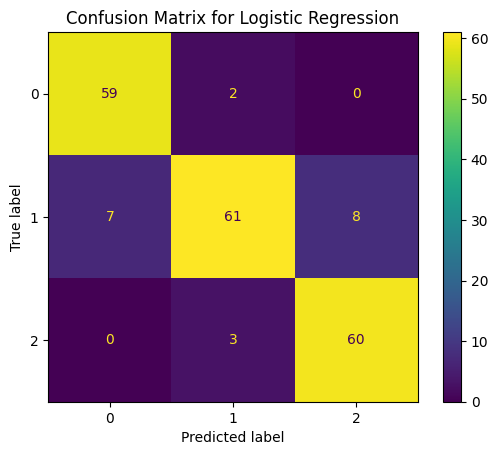

In [13]:

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100], 
    'solver': ['lbfgs', 'saga'],  
    'max_iter': [1000, 2000]  
}

logistic_model = LogisticRegression(multi_class='ovr')

grid_search = GridSearchCV(logistic_model, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train_scaled, y_train)


best_model = grid_search.best_estimator_
y_pred_test = best_model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred_test)
f1_macro = f1_score(y_test, y_pred_test, average='macro')
conf_matrix = confusion_matrix(y_test, y_pred_test)

print(f"Best Hyperparameters: {grid_search.best_params_}")
print(f"Improved Accuracy: {accuracy:.4f}")
print(f"Macro F1 Score: {f1_macro:.4f}")

disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix)
disp.plot(cmap='viridis')
plt.title('Confusion Matrix for Logistic Regression')
plt.show()


## Part C: Am I a zombie?
My own measurements, run through the from-scratch OvA classifier.

In [14]:
# Fill in these values (honestly)
height = 178               # Height in cm
weight = 73.4               # Weight in kg
screen_time = 3         # Screen time in hours per day
junk_food_days = 2      # Junk food consumption in days per week
physical_activity = 6    # Physical activity in hours per week
task_completion = 4      # Task completion on a scale (example range: 1-10)

In [15]:

scaler = StandardScaler()
scaler.fit(X_train)

test_point = np.array([[height, weight, screen_time, junk_food_days, physical_activity, task_completion]])

test_point_scaled = scaler.transform(test_point)

print("Transformed Test Point:", test_point_scaled)

test_point = np.array([height, weight, screen_time, junk_food_days, physical_activity, task_completion])
test_point = scaler.transform(test_point)  

Transformed Test Point: [[ 1.7753952   1.01651937 -1.39810392 -1.61048988  0.31907412 -0.33339136]]


In [16]:

labels = {0: "Human", 1: "Needs Further Testing", 2: "Zombie"}
probs=[]
for i in range(3):  
    prob, y_pred_class = classifiers[i].predict(test_point.reshape(1,-1))   # predict returns (probability, label)    
    probs.append(prob)
combined_probs = np.column_stack([p for p in probs])
multi_class_pred = np.argmax(combined_probs, axis=1)
print("Prediction:", labels[multi_class_pred[0]])

Prediction: Human


## Summary
- **From scratch, OvA reaches 88.0% accuracy (macro F1 0.880).** Tuned scikit-learn `LogisticRegression` (C = 10, lbfgs) reaches **90.0% (macro F1 0.901)**, so the hand-written version is within 2 points.
- **The end classes are easy, the middle class is hard.** The class-0 and class-2 classifiers score 96.5% and 95.0% accuracy. The class-1 ("needs further tests") classifier never predicts positive (F1 = 0): a single straight boundary can't separate the middle band from both ends at once.
- **OvA still recovers most of the middle class.** Because the final prediction takes the *highest* probability rather than a 0.5 cutoff, 55 of the 76 class-1 test cases are classified correctly. The other 21 are split 12 → human and 9 → zombie, and the remaining 3 errors are zombies flagged for further tests. No human is ever classified as a zombie, or vice versa.
- **Part C:** my own measurements are classified as **Human**.
- **Possible improvement:** since the classes come from an ordered score, ordinal or softmax (multinomial) regression, or simply thresholding the linear regression's predicted score, would fit the structure of the problem better than OvA.